# Machine Learning

> Field of study that gives computers the ability to learn without being explicitly programmed - Arthur Samuel

In general, the more opportunities you give a learning algorithm to learn, the better it will perform

## Types of machine learning algorithms

- Supervised learning
- Unsupervised learning
- Recommender systems
- Reinforcement learning

### Supervised learning

Algorithms that learn 

$$X  \to Y$$

i.e., input to output mappings, the key characteristic is that we give the algorithm examples to learn from that include the "right answers", i.e., the correct label $y$ for a given input $x$. Let's see some examples

<p align="center">
  <img src="images/applications_supervised.png" alt="supervised learning applications" width="500"/>
</p>

We have two main types of algorithms within this context: regression and classification. The regression algorithms learns to predict numbers out of a given number of numerical inputs. 

A classification problem can be seen via an the example: breast cancer detection. Suppose we're trying to build a machine learning system so the doctors can have a diagnostic tool to detect breast cancer; using a patient medical records the machine learning system tries to figure out if a tumor that is a lump is malignant or if that tumor is benign.

<p align="center">
  <img src="images/tumor_classification.png" alt="tumor classification data" width="300"/>
</p>

So we can plot our data in a graph

 <p align="center">
  <img src="images/tumor_classification_graph.png" alt="tumor classification graph" width="500"/>
</p>

Hence, classification algorithms predict categories which are not required to be strictly numerical, for example, tumor prediction, element in image recognition. In classification settings the words class or category are often used interchangeably. The difference between classification and regression is that classification predicts a small, finite different set of possible output categories.      

### Unsupervised learning

With unsupervised learning we look to find something interesting in unlabeled data. We do not provide the learning algorithm with the right answer for each data, instead we want the algorithm to find insights in the data and group in in clusters or extract valuable patterns from it.

* Clusering: group similar data points together
* Anomaly detection: find unusaul data points
* Dimensionality reduction: compress data using fewer numbers

Data comes with inputs $x$, but not output labels $y$. Algorithm has to find structure in the data. 

**Notation.**

* Training set: data used to train the model, $x$ is the input variable (feature), $y$ is known as the output or target variable. The most used notation to describe each training example is

$$(x^{(i)}, y^{(i)}) = i\text{th training example}$$

Linear Regression

With a univariate linear regression algorithm we try to fit a straight line to our data, and based on this make predictions. We usually represent $f$, our model, as

$$f_{w,b}(x)=wx + b$$

### Model Representation Lab

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
x_train = np.array([1.0, 2.0])
y_train = np.array([300, 500])
print(f"x_train = {x_train}")
print(f"y_train = {y_train}")

x_train = [1. 2.]
y_train = [300 500]


In [3]:
# m is the number of training examples
print(f"x_train.shape: {x_train.shape}")
m = x_train.shape[0]
print(f"Number of training examples is: {m}")

x_train.shape: (2,)
Number of training examples is: 2


In [4]:
i = 0

x_i = x_train[i]
y_i = y_train[i]
print(f"(x^({i}), y^({i})) = ({x_i}, {y_i})")

(x^(0), y^(0)) = (1.0, 300)


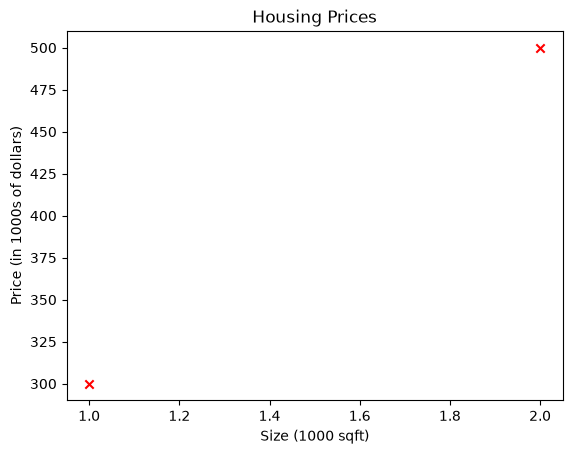

In [5]:
# Plot the data points
plt.scatter(x_train, y_train, marker='x', c='r')
# Set the title
plt.title("Housing Prices")
# Set the y-axis label
plt.ylabel("Price (in 1000s of dollars)")
# Set the x-axis label
plt.xlabel("Size (1000 sqft)")
plt.show()

In [6]:
def compute_model_output(x: np.array, w: float, b: float) -> np.array:
    """
    Computes the prediction of a linear model
    Args:
        x (ndarray (m,)): Data, m examples
        w, b (scalar)   : Model parameters
    Returns:
        f_wb (ndarray (m,)): model prediction 
    """
    m = x.shape[0]
    f_wb = np.zeros(m)
    for i in range(m):
        f_wb[i] = w * x[i] + b

    return f_wb

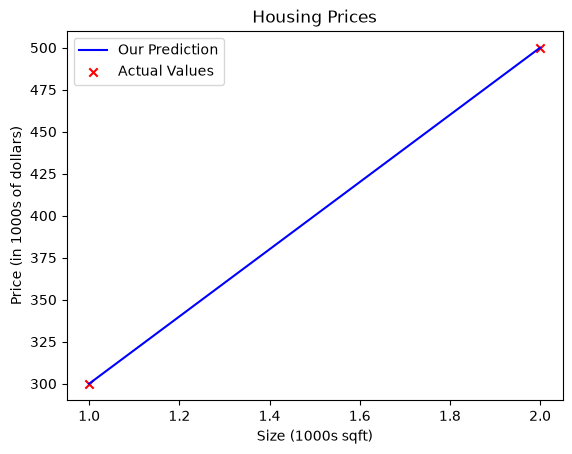

In [9]:
w, b = 200, 100

tmp_f_wb = compute_model_output(x_train, w, b)

# Plot our model prediction
plt.plot(x_train, tmp_f_wb, c='b', label='Our Prediction')
# Plot the data points
plt.scatter(x_train, y_train, marker='x', c='r', label='Actual Values')

# Set the title
plt.title("Housing Prices")
# Set the x and y labels
plt.ylabel("Price (in 1000s of dollars)")
plt.xlabel("Size (1000s sqft)")
plt.legend()
plt.show()

Cost function formula

Our cost function takes the prediction $\hat{y}$ and compares it to the target $y$, i.e., 

$$J(w, b)= \frac{1}{2m}\sum_{i=1}^{m}{(\hat{y}^{(i)}-y^{(i)})^2}$$
$$J(w, b)= \frac{1}{2m}\sum_{i=1}^{m}{(f_{w,b}(x^{(i)})-y^{(i)})^2}$$






In [ ]:
def compute_cost(x, y, w, b):
    """
    Computes the cost function for linear regresion.

    Args:
        x (ndarray (m,)): Data, m examples.
        y (ndarray (m,)): target values
        w, b (scalar)   : model parameters
    
    Returns
        total_cost (float): The cost of using w, b as the parameters for linear regression
            to fit the data points in x and y
    """
    # Number of traning examples
    m = x.shape[0]

    cost_sum = 0
    for i in range(m):
        f_wb = w * x[i] + b
        cost = (f_wb - y[i]) ** 2
        cost_sum = cost_sum + cost

    total_cost = (1 / (2 * m)) * cost_sum
    return total_cost
